![Original abstract globe and synthetic weather streamlines](assets/splash.png)

# A three-dimensional terrain scene

**Lesson 16 · Original synthetic data · Independent educational project**

## Objectives

Create a surface from a grid; describe vertical exaggeration explicitly.

[Previous](15-projections.ipynb) · [Notebook source](https://github.com/jltobias/JupyterLite-Destination-Earth-Digital-Twin/blob/main/content/16-terrain.ipynb) · [Next](17-globe.ipynb)

[Open this notebook in JupyterLite](https://jltobias.github.io/JupyterLite-Destination-Earth-Digital-Twin/lab/index.html?path=16-terrain.ipynb) — public deployment pending until verified. For a local build, open the matching filename from the Lab file browser.

Run every code cell in order. The first run in JupyterLite downloads browser packages; it needs an internet connection. No account or credentials are used. The interactive visual lessons use ipywidgets, and the gallery provides additional live controls.

## Prepare the browser-sized environment

The shared `earthlab.py` helper lives beside every notebook. The same source notebook is used by the book and Lab.

In [1]:
import sys
if sys.platform == "emscripten":
    import piplite
    await piplite.install(["numpy", "matplotlib", "pandas", "xarray", "ipywidgets"])
import numpy as np
import matplotlib.pyplot as plt
import earthlab as lab
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
print(lab.PROVENANCE)

Original synthetic teaching data; not observations or DestinE model output


## Worked experiment

Run this original experiment and inspect both its figure and numerical checks.

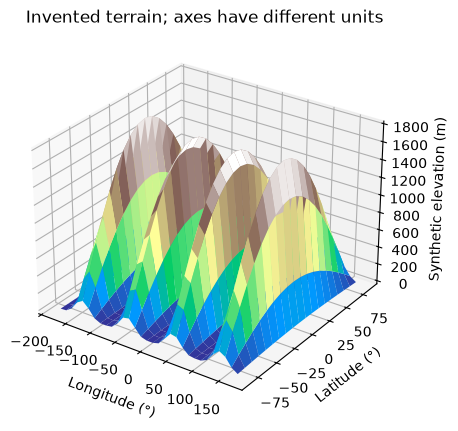

Height range (m): 6.771275128406897e-61 1790.7766278345166


In [2]:
cube = lab.synthetic_cube(nlat=19, nlon=31)
x, y = np.meshgrid(cube["lon"], cube["lat"])
z = cube["elevation"]
assert np.all(z >= 0) and z.shape == x.shape
fig = plt.figure(figsize=(8, 5)); ax = fig.add_subplot(projection="3d")
ax.plot_surface(x, y, z, cmap="terrain", linewidth=0, antialiased=True)
ax.set(xlabel="Longitude (°)", ylabel="Latitude (°)", zlabel="Synthetic elevation (m)", title="Invented terrain; axes have different units")
ax.view_init(elev=28, azim=-55)
plt.show()
print("Height range (m):", z.min(), z.max())

## Exercise

Change the viewing angle and box aspect ratio. Document how apparent steepness changes even though the numbers do not.

Add a code cell with your modification and at least one assertion that would catch an incorrect result. Keep the original experiment as a reference.

## Interactive Lab experiment

Move the time slider, change the variable or rotate the 3D view. This widget runs in a Python kernel in Lab; the published book preserves a static output. Explain which control changes the data and which only changes its display.

In [3]:
import ipywidgets as widgets
from IPython.display import display
interactive_cube = lab.synthetic_cube(nlat=19, nlon=31)
def explore(day=0, variable="temperature", azimuth=-55):
    units = interactive_cube["units"][variable]
    field = interactive_cube[variable][day]
    bounds = (245, 300) if variable == "temperature" else (0, 8)
    fig = plt.figure(figsize=(8, 4))
    ax = fig.add_subplot(projection="3d")
    xx, yy = np.meshgrid(interactive_cube["lon"], interactive_cube["lat"])
    norm = plt.Normalize(*bounds)
    ax.plot_surface(xx, yy, interactive_cube["elevation"], facecolors=plt.cm.viridis(norm(field)))
    ax.view_init(elev=28, azim=azimuth)
    ax.set(xlabel="Longitude", ylabel="Latitude", zlabel="Synthetic elevation (m)")
    fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap="viridis"), ax=ax, shrink=.6, label=units)
    fig.suptitle(f"Synthetic {variable}, day {day}")
    plt.tight_layout(); plt.show()
controls = widgets.interactive(explore, day=widgets.IntSlider(min=0,max=59,value=0),
                               variable=["temperature", "precipitation"], azimuth=(-180,180,5))
display(controls)

interactive(children=(IntSlider(value=0, description='day', max=59), Dropdown(description='variable', options=…

## Interpretation and limits

This scene uses degrees horizontally and meters vertically, so it is a visual exploration rather than a physically scaled terrain model. No real elevation data are used.

**Check your reasoning:** identify one result the code establishes and one conclusion the demonstration cannot establish.

## References and provenance

- [Conceptual or software reference](https://matplotlib.org/stable/users/explain/toolkits/mplot3d.html) — linked for background; no text, external notebook code or data were copied.
- [Destination Earth initiative source index](https://github.com/destination-earth/DestinE).
- Generated arrays and equations: original project teaching material, CC BY 4.0; helper code: MIT. No authentic DestinE outputs or observational datasets are used.
- The abstract splash was generated for this project. See the repository's [attribution record](https://github.com/jltobias/JupyterLite-Destination-Earth-Digital-Twin/blob/main/ATTRIBUTIONS.md).